## Experiment with Missing Data

A second version of the original hockey dataset was generated separately to maintain the raw dataset.

Cells containing non-missing data from the input features in `GF` (Goals For) and `GA` (Goals Against) were randomly chosen for about 5% of the cells and converted into `NaN`.

A fixed random seed was used in order to get repeatable results. Random sampling was done without replacement.

`Wins` and `Win %` columns were exempted from generating any missing values, as per project guidelines.

The original missing value of 224 values in `OT Losses` column was retained.

The updated dataset was stored as `data/hockey_teams_missing.csv`, while the original `data/hockey_teams_raw.csv` was kept intact.

**Code Implementation:** `src/preprocessing.py`

In [27]:
import pandas as pd

raw = pd.read_csv("../data/hockey_teams_raw.csv")
modified = pd.read_csv("../data/hockey_teams_missing.csv")

print("Original missing values:")
print(raw.isnull().sum())

print("\nModified missing values:")
print(modified.isnull().sum())

print("\nNew missing values:")
print(
    modified[raw.columns].isnull().sum()
    - raw.isnull().sum()
)

Original missing values:
Team Name         0
Year              0
Wins              0
Losses            0
OT Losses       224
Win %             0
GF                0
GA                0
+/-               0
collected_at      0
dtype: int64

Modified missing values:
Team Name         0
Year              0
Wins              0
Losses            0
OT Losses       224
Win %             0
GF               28
GA               30
+/-               0
collected_at      0
Team_Status       0
dtype: int64

New missing values:
Team Name        0
Year             0
Wins             0
Losses           0
OT Losses        0
Win %            0
GF              28
GA              30
+/-              0
collected_at     0
dtype: int64


## Data Cleaning and Exploratory Analysis

In [28]:
import pandas as pd

df = pd.read_csv("../data/hockey_teams_missing.csv")
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
print(df.describe().to_string())
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print("\nMissing values:")
print(missing_summary.to_string())

print("\nExact duplicate rows:", df.duplicated().sum())

Dataset shape: (582, 11)

Data types:
Team Name           str
Year              int64
Wins              int64
Losses            int64
OT Losses       float64
Win %           float64
GF              float64
GA              float64
+/-               int64
collected_at        str
Team_Status       int64
dtype: object

Summary statistics:
              Year        Wins      Losses   OT Losses       Win %          GF          GA         +/-  Team_Status
count   582.000000  582.000000  582.000000  358.000000  582.000000  554.000000  552.000000  582.000000   582.000000
mean   2000.907216   36.943299   32.353952    7.460894    0.458519  234.456679  234.186594    0.000000     0.398625
std       6.330674    8.926081    8.411439    3.610191    0.102237   40.885972   42.057945   45.277458     0.490037
min    1990.000000    9.000000   11.000000    0.000000    0.119000  115.000000  119.000000 -196.000000     0.000000
25%    1996.000000   31.000000   27.000000    5.000000    0.390000  211.000000  207

### Data Quality Inspection – Analysis

The loaded dataset comprises 582 rows and 11 columns and captures historical seasons of teams from the year 1990.

The presence of missing values was detected in the features GF (4.81%) and GA (5.15%). They were added during the experiment with missing data. The OT Losses feature has 224 missing values (38.49%) already.

There are no duplicate rows to handle.

The numerical description reveals a high variation in team performance. The average value of the Wins feature is around 36.94, and the Winning % feature is approximately 0.459.

The target feature has approximately 39.86% of winning seasons and 60.14% non-winning seasons.

Missing values will be addressed using the preprocessing pipeline that will be fit only on the training data.

## Numerical Distributions, Skewness and Outlier Analysis

Skewness:
Year   -0.032
GF      0.257
GA      0.387
+/-    -0.578


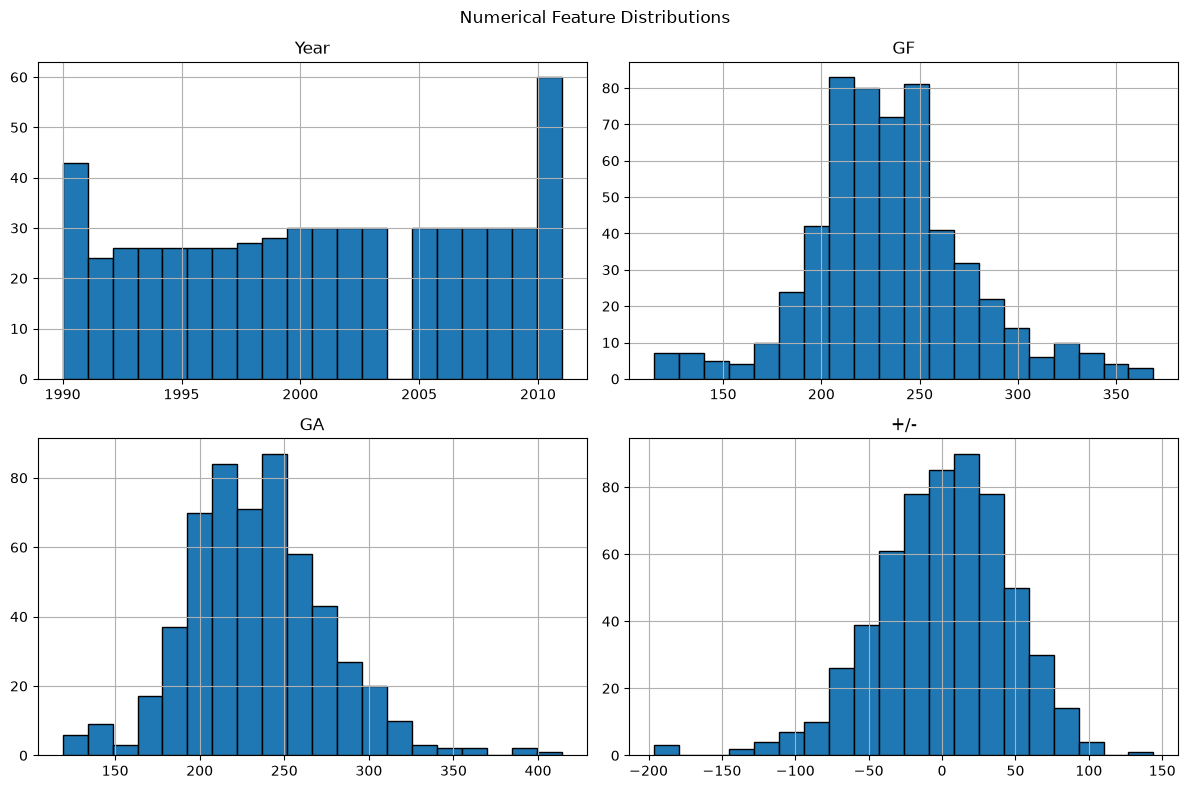

<Figure size 1200x600 with 0 Axes>

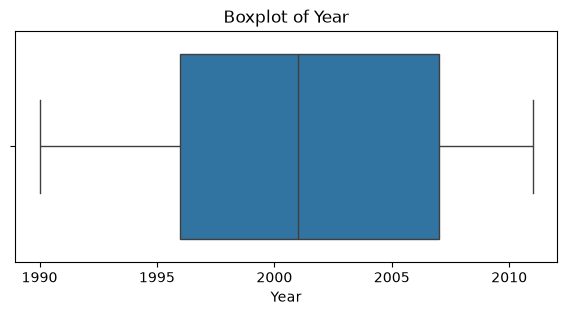

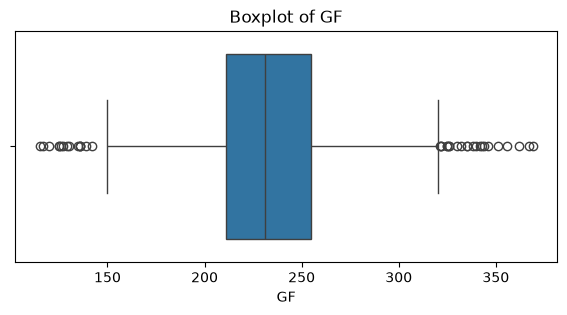

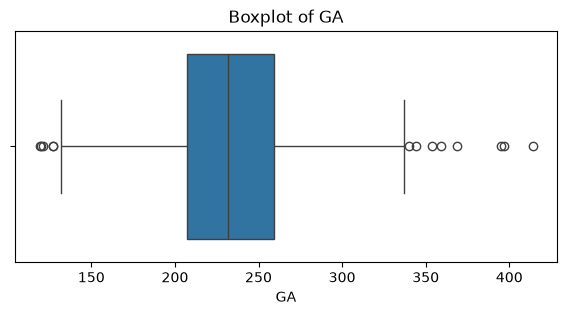

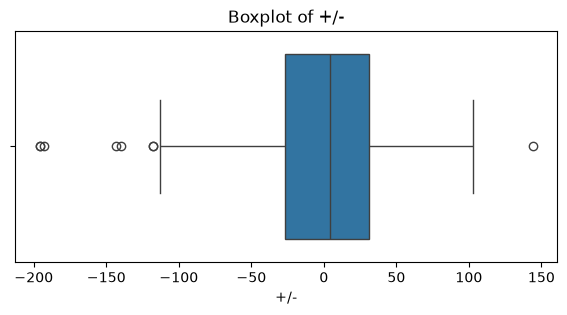

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/hockey_teams_missing.csv")

# Numerical features relevant to classification
numeric_cols = ["Year", "GF", "GA", "+/-"]

# Calculate skewness
print("Skewness:")
print(df[numeric_cols].skew().round(3).to_string())

# Create histograms
df[numeric_cols].hist(
    bins=20,
    figsize=(12, 8), #Sets the overall figure dimensions to 12 inches wide and 8 inches tall.
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout() #Adjusts spacing so that chart titles, axis labels and plots are less likely to overlap.
plt.show()
plt.figure(figsize=(12, 6))

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


In [30]:
outlier_results = []

for col in ["GF", "GA", "+/-"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower) | (df[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outliers": outlier_count
    })

outlier_df = pd.DataFrame(outlier_results)

print(outlier_df.to_string(index=False))

Feature    Q1     Q3   IQR  Lower Bound  Upper Bound  Outliers
     GF 211.0 254.75 43.75      145.375      320.375        37
     GA 207.0 259.00 52.00      129.000      337.000        13
    +/- -27.0  31.00 58.00     -114.000      118.000         8


### Skewness and Outlier Analysis – Interpretation

Analysis of skewness was done using the numerical classification variables: Year, GF, GA, and +/-.

The calculated skewness values were -0.032 for Year, 0.257 for GF, 0.387 for GA, and -0.578 for +/-.

The numerical variables Year, GF, and GA had slightly skewed or nearly symmetric distributions, whereas +/- had moderately negative skewness.

The number of potential outliers based on IQR criteria for GF, GA, and +/- was 37, 13, and 8 respectively.

They were not considered automatic outliers as unusually low or high goals could indicate legitimate hockey performance in history, not entry mistakes.

Treatment approach: Potential outliers will be kept as they are. No skewness transformations are to be performed at the moment since there is no evidence that it is needed.

Further analysis and treatment of potential outliers and transformations, if any, will be conducted solely on the basis of training data.

Plots of histograms and boxplots have been utilized for checking the distribution and detecting outliers visually.

### Year — Boxplot Interpretation

Year variable varies between 1990 and 2011, with the median year being about 2001.

The first quartile is about 1996 while the third quartile is about 2007, showing that 50 percent of teams and their seasons lie in this range.

Outliers could not be found based on the 1.5 × IQR test.

With the skewness value being −0.032, the distribution appears to be symmetric.

**Treatment Decision:** All Year values are kept as they are without any modification because the values are legitimate and there is no issue of skewness.

## Chronological Train-Test Split

In [31]:
import pandas as pd
df = pd.read_csv("../data/hockey_teams_missing.csv")
df = df.sort_values("Year").reset_index(drop=True)

# Find the year boundary closest to 80% training data
years = sorted(df["Year"].unique())
target_train_rows = len(df) * 0.80 # 80% training data and 20% test data

best_difference = float("inf")
cutoff_year = None
for year in years[1:]:

    train_count = (df["Year"] < year).sum()

    difference = abs(train_count - target_train_rows)

    if difference < best_difference:
        best_difference = difference
        cutoff_year = year

print("Best cutoff year:", cutoff_year)

# Split complete seasons
train_df = df[df["Year"] < cutoff_year].copy()
test_df = df[df["Year"] >= cutoff_year].copy()

# Define classification input features
feature_cols = ["Team Name", "Year", "GF", "GA", "+/-"]

X_train = train_df[feature_cols]
X_test = test_df[feature_cols]

# Classification target
y_train = train_df["Team_Status"]
y_test = test_df["Team_Status"]

# Display results
print("First test year:", cutoff_year)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining percentage:",
      round(len(train_df) / len(df) * 100, 2))

print("Testing percentage:",
      round(len(test_df) / len(df) * 100, 2))

print("\nTraining years:",
      train_df["Year"].min(), "-", train_df["Year"].max())

print("Testing years:",
      test_df["Year"].min(), "-", test_df["Year"].max())

print("\nMissing values in training:")
print(X_train.isnull().sum())

print("\nMissing values in testing:")
print(X_test.isnull().sum())

Best cutoff year: 2008
First test year: 2008
Training shape: (462, 5)
Testing shape: (120, 5)

Training percentage: 79.38
Testing percentage: 20.62

Training years: 1990 - 2007
Testing years: 2008 - 2011

Missing values in training:
Team Name     0
Year          0
GF           19
GA           23
+/-           0
dtype: int64

Missing values in testing:
Team Name    0
Year         0
GF           9
GA           7
+/-          0
dtype: int64


### Chronological Train-Test Split - Results

The data was split into training and testing samples chronologically by Year column.

Cutoff year chosen is **2008**, which results in:

- **Training:** 462 rows (79.38%) containing seasons 1990-2007.
- **Testing:** 120 rows (20.62%) containing seasons 2008-2011.

Both the training and testing samples consist of five features: Team_Name, Year, GF, GA, and +/-.

Team_Status is the classification target. Wins, Win %, Losses, and OT_Losses were not included in the feature set to avoid target leakage.

There are 19 missing GF and 23 missing GA in the training sample. There are 9 missing GF and 7 missing GA in the testing sample.

Missing values were deliberately kept here since preprocessing parameters need to be estimated only from the training set.

## Missing-Value Imputation Using SimpleImputer

In [32]:
import pandas as pd
from sklearn.impute import SimpleImputer
# cols containing missing values 
impute_cols = ["GF", "GA"]


imputer = SimpleImputer(strategy="median") # imputer object 

imputer.fit(X_train[impute_cols])  # Calculates the median of each column

print("Training medians:")
for col, median in zip(impute_cols, imputer.statistics_):  # imputer.statistics_ is a  array that stores values from .fit()
    print(f"{col}: {median}")

X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()


X_train_imputed[impute_cols] = imputer.transform(   # replaces nan with the calculated medians
    X_train[impute_cols]
)

X_test_imputed[impute_cols] = imputer.transform(
    X_test[impute_cols]
)


print("\nBefore imputation - Training:")
print(X_train[impute_cols].isnull().sum())

print("\nAfter imputation - Training:")
print(X_train_imputed[impute_cols].isnull().sum())

print("\nBefore imputation - Testing:")
print(X_test[impute_cols].isnull().sum())

print("\nAfter imputation - Testing:")
print(X_test_imputed[impute_cols].isnull().sum())

Training medians:
GF: 234.0
GA: 233.0

Before imputation - Training:
GF    19
GA    23
dtype: int64

After imputation - Training:
GF    0
GA    0
dtype: int64

Before imputation - Testing:
GF    9
GA    7
dtype: int64

After imputation - Testing:
GF    0
GA    0
dtype: int64


### Results and Interpretations for Median Imputation

The missing values in the GF and GA variables were filled using the `SimpleImputer` function in Scikit-Learn with the median method.

The imputer was fit on the training data only (1990-2007). Training medians obtained were:

- GF: 234.0
- GA: 233.0

In the training dataset, before imputation, there were 19 missing GF and 23 missing GA values. In the testing data, there were 9 missing GF and 7 missing GA values.

After imputation, the GF and GA variables had no missing values in both datasets.

The same medians were used for both the datasets, thereby avoiding any leakage of information from the testing dataset.

Median imputation was used since it is not impacted by outliers as compared to mean imputation. The initial missing value dataset was kept intact, and the imputation was done on separate working datasets.

## One-Hot Encoding of Team Name

In [33]:
from sklearn.preprocessing import OneHotEncoder

# Create encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# learn team names from training data only (only unique)
encoder.fit(X_train[["Team Name"]])

# transform training and testing data
train_encoded = encoder.transform(X_train[["Team Name"]])
test_encoded = encoder.transform(X_test[["Team Name"]]) #.transform() converts each team name into binary values according to the categories learned during .fit().

# Display results
print("Unique training teams:", len(encoder.categories_[0]))
print("Encoded training shape:", train_encoded.shape)
print("Encoded testing shape:", test_encoded.shape)

print("\nEncoded column names:")
print(encoder.get_feature_names_out(["Team Name"]))

Unique training teams: 35
Encoded training shape: (462, 35)
Encoded testing shape: (120, 35)

Encoded column names:
['Team Name_Anaheim Ducks' 'Team Name_Atlanta Thrashers'
 'Team Name_Boston Bruins' 'Team Name_Buffalo Sabres'
 'Team Name_Calgary Flames' 'Team Name_Carolina Hurricanes'
 'Team Name_Chicago Blackhawks' 'Team Name_Colorado Avalanche'
 'Team Name_Columbus Blue Jackets' 'Team Name_Dallas Stars'
 'Team Name_Detroit Red Wings' 'Team Name_Edmonton Oilers'
 'Team Name_Florida Panthers' 'Team Name_Hartford Whalers'
 'Team Name_Los Angeles Kings' 'Team Name_Mighty Ducks of Anaheim'
 'Team Name_Minnesota North Stars' 'Team Name_Minnesota Wild'
 'Team Name_Montreal Canadiens' 'Team Name_Nashville Predators'
 'Team Name_New Jersey Devils' 'Team Name_New York Islanders'
 'Team Name_New York Rangers' 'Team Name_Ottawa Senators'
 'Team Name_Philadelphia Flyers' 'Team Name_Phoenix Coyotes'
 'Team Name_Pittsburgh Penguins' 'Team Name_Quebec Nordiques'
 'Team Name_San Jose Sharks' 'Team N

In [34]:
training_teams = set(X_train["Team Name"])
testing_teams = set(X_test["Team Name"])

unknown_teams = testing_teams - training_teams

print("Unseen teams in testing:", unknown_teams)
print("Number of unseen teams:", len(unknown_teams))

Unseen teams in testing: set()
Number of unseen teams: 0


In [35]:
import pandas as pd

encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoder.get_feature_names_out(["Team Name"]),
    index=X_train.index
)

print(encoded_df.head().to_string())

   Team Name_Anaheim Ducks  Team Name_Atlanta Thrashers  Team Name_Boston Bruins  Team Name_Buffalo Sabres  Team Name_Calgary Flames  Team Name_Carolina Hurricanes  Team Name_Chicago Blackhawks  Team Name_Colorado Avalanche  Team Name_Columbus Blue Jackets  Team Name_Dallas Stars  Team Name_Detroit Red Wings  Team Name_Edmonton Oilers  Team Name_Florida Panthers  Team Name_Hartford Whalers  Team Name_Los Angeles Kings  Team Name_Mighty Ducks of Anaheim  Team Name_Minnesota North Stars  Team Name_Minnesota Wild  Team Name_Montreal Canadiens  Team Name_Nashville Predators  Team Name_New Jersey Devils  Team Name_New York Islanders  Team Name_New York Rangers  Team Name_Ottawa Senators  Team Name_Philadelphia Flyers  Team Name_Phoenix Coyotes  Team Name_Pittsburgh Penguins  Team Name_Quebec Nordiques  Team Name_San Jose Sharks  Team Name_St. Louis Blues  Team Name_Tampa Bay Lightning  Team Name_Toronto Maple Leafs  Team Name_Vancouver Canucks  Team Name_Washington Capitals  Team Name_Winni

In [36]:
print("Original team names:")
print(X_train[["Team Name"]].head())

print("\nEncoded team names:")
print(encoded_df.head())

Original team names:
            Team Name
0       Boston Bruins
1      Buffalo Sabres
2      Calgary Flames
3  Chicago Blackhawks
4   Detroit Red Wings

Encoded team names:
   Team Name_Anaheim Ducks  Team Name_Atlanta Thrashers  \
0                      0.0                          0.0   
1                      0.0                          0.0   
2                      0.0                          0.0   
3                      0.0                          0.0   
4                      0.0                          0.0   

   Team Name_Boston Bruins  Team Name_Buffalo Sabres  \
0                      1.0                       0.0   
1                      0.0                       1.0   
2                      0.0                       0.0   
3                      0.0                       0.0   
4                      0.0                       0.0   

   Team Name_Calgary Flames  Team Name_Carolina Hurricanes  \
0                       0.0                            0.0   
1         

### Verification of Unknown Teams’ Category

Both datasets were compared to find teams’ names which appear only in the testing timeframe.

No unknown teams’ category names were found in the testing dataset. Thus, all teams from the testing set belonged to one of 35 categories acquired during the training procedure.

The parameter `handle_unknown="ignore"` was used in order to make sure that there is no problem with handling unknown categories in future datasets.

This proves that the same One-Hot Encoding schema can be applied to both training and testing sets of data.

## Numerical Feature Scaling using StandardScaler

In [37]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ["Year", "GF", "GA", "+/-"]

# scaler object
scaler = StandardScaler()

scaler.fit(X_train_imputed[numeric_cols]) #Calculates and stores the mean and standard deviation

X_train_scaled = scaler.transform(X_train_imputed[numeric_cols])  # uses the mean and sd to change the values
X_test_scaled = scaler.transform(X_test_imputed[numeric_cols])


print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("\nTraining means:", scaler.mean_)
print("Training standard deviations:", scaler.scale_)

Scaled training shape: (462, 4)
Scaled testing shape: (120, 4)

Training means: [1998.67532468  235.26839827  234.99350649    0.        ]
Training standard deviations: [ 5.09079866 43.1403809  44.24985583 47.42006261]


In [38]:
import pandas as pd

scaled_train_df = pd.DataFrame(
    X_train_scaled,
    columns=numeric_cols,
    index=X_train.index
)

print("Original numerical features:")
print(X_train_imputed[numeric_cols].head())

print("\nScaled numerical features:")
print(scaled_train_df.head())

print("\nScaled training means:")
print(scaled_train_df.mean().round(4))

print("\nScaled training standard deviations:")
print(scaled_train_df.std(ddof=0).round(4))

Original numerical features:
   Year     GF     GA  +/-
0  1990  299.0  264.0   35
1  1990  292.0  233.0   14
2  1990  344.0  263.0   81
3  1990  284.0  211.0   73
4  1990  273.0  298.0  -25

Scaled numerical features:
       Year        GF        GA       +/-
0 -1.704119  1.477307  0.655516  0.738084
1 -1.704119  1.315046 -0.045051  0.295234
2 -1.704119  2.520414  0.632917  1.708138
3 -1.704119  1.129605 -0.542228  1.539433
4 -1.704119  0.874624  1.423880 -0.527203

Scaled training means:
Year    0.0
GF     -0.0
GA      0.0
+/-     0.0
dtype: float64

Scaled training standard deviations:
Year    1.0
GF      1.0
GA      1.0
+/-     1.0
dtype: float64


### StandardScaler - Outcome and Interpretation

The StandardScaler technique has been implemented on the numeric attributes ‘Year’, ‘GF’, ‘GA’, and ‘+/-’.

The scaler has been fit only on the imputed training data. The obtained training mean and standard deviation have been used for transformation of both training and testing datasets without data leakage.

The verification has proved that all four standardized training features are characterized by mean close to zero and unit standard deviation.

The original values have been saved separately, and the standardized features will be included in the final pre-processing pipeline.

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = ["Team Name"]
numeric_cols = ["Year", "GF", "GA", "+/-"]
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # performs steps in a sequence
    # first fill missing values with median then standarize it
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("numerical", numeric_pipeline, numeric_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (462, 39)
Processed testing shape: (120, 39)


### Combined Preprocessing Pipeline — Results

A `ColumnTransformer` object was defined to apply preprocessing to both categorical and numerical variables.

The categorical variable “Team Name” was processed through One-Hot Encoding using `handle_unknown="ignore"` parameter.

The numerical variables “Year”, “GF”, “GA”, and “+/-"” were processed through a pipeline with median imputation step and then StandardScaler.

Preprocessing was applied only to the training set and then used to preprocess the testing set to avoid any data leakage.

The final training set consisted of **462 observations with 39 features** while the testing set contained **120 observations with the same number of 39 features**.

The preprocessing pipeline is ready to be used in machine learning pipelines for classification.

In [40]:
import numpy as np

print("Missing values in training:",
      np.isnan(X_train_processed.toarray()
               if hasattr(X_train_processed, "toarray")
               else X_train_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed.toarray()
               if hasattr(X_test_processed, "toarray")
               else X_test_processed).sum())



Missing values in training: 0
Missing values in testing: 0


### Final Preprocessing Verification

The final preprocessing transformer was fit on the training dataset and applied to both the training and test datasets.

The preprocessed training dataset comprises 462 samples and 39 features, while the preprocessed test dataset comprises 120 samples and 39 features.

The final verification was done for checking that there are no more missing values in the preprocessed datasets.

All the preprocessing parameters, such as median, category for categorical encoding, and statistics for scaling, have been computed using the training dataset alone.

## Classification Model 1: Logistic Regression

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline #  pipeline connects multiple operations and executes them in sequence
from sklearn.base import clone

logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=1000)) #maximum number of optimization iterations
])

In [42]:
# earlier seasons for model development
X_dev = X_train[X_train["Year"] < 2005]
y_dev = y_train.loc[X_dev.index]

# later training seasons for validation
X_val = X_train[X_train["Year"] >= 2005]
y_val = y_train.loc[X_val.index]

print("Development shape:", X_dev.shape)
print("Validation shape:", X_val.shape)
#X_dev and y_dev must correspond to exactly the same observations
logistic_model.fit(X_dev, y_dev) 

print("Logistic Regression trained successfully!")

Development shape: (372, 5)
Validation shape: (90, 5)
Logistic Regression trained successfully!


### Logistic Regression – Model Building

Logistic Regression was chosen as the first classification model which will determine whether a hockey team had a winning season (variable `Team_Status` = 1).

A Scikit-Learn Pipeline was developed for the combination of preprocessing and Logistic Regression.

The pre-processing step includes median imputation, One-Hot Encoding for teams’ names, and StandardScaler normalization for numerical features.

A chronological split of train data into development and validation datasets was done. Seasons up to 2005 were used for development, and 2005 to 2007 were allocated for validation.

It guarantees that pre-processing and model training will be done using only old data.

In [43]:

y_val_pred = logistic_model.predict(X_val)

print("First 10 actual values:")
print(y_val.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_val_pred[:10])

First 10 actual values:
[1 1 0 1 1 1 0 0 1 1]

First 10 predicted values:
[0 0 0 1 1 1 0 0 1 1]


In [44]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(y_val, y_val_pred, zero_division=0)
recall = recall_score(y_val, y_val_pred, zero_division=0)
f1 = f1_score(y_val, y_val_pred, zero_division=0)

print("Logistic Regression Validation Results")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
#Accuracy	How many total predictions were correct
#Precision	When the model predicts winning how often is it correct?
#Recall	How many actual winning seasons were identified?
#F1-score	How well are precision and recall balanced?

Logistic Regression Validation Results
Accuracy: 0.6778
Precision: 1.0
Recall: 0.4727
F1-score: 0.642


### Logistic Regression — Confusion Matrix

Confusion Matrix:
[[35  0]
 [29 26]]


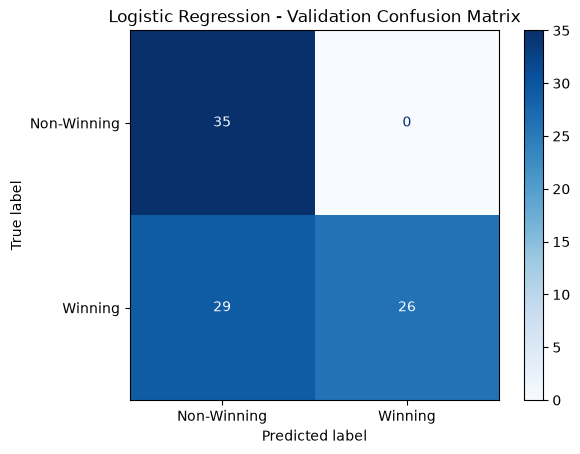

In [45]:

# confusion matrix compares actual classes with the predicted classes by the model
#TN — True Negative	Correctly predicted non-winning seasons
#FP — False Positive	Incorrectly predicted winning seasons
#FN — False Negative	Incorrectly predicted non-winning seasons
#TP — True Positive	Correctly predicted winning seasons
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred)


print("Confusion Matrix:")
print(cm)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Winning", "Winning"] # object for plotting
)
disp.plot(cmap="Blues") # blue color scale

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()
#[[TN FP]
#[FN TP]
#]

In [46]:
y_val_prob = logistic_model.predict_proba(X_val)[:, 1] # all rows and second column

print("First 10 predicted probabilities:")
print(y_val_prob[:10], 4)

First 10 predicted probabilities:
[3.98353287e-01 1.54813202e-01 6.51024268e-03 6.04362930e-01
 5.29428770e-01 6.45554734e-01 6.93141833e-04 1.43366563e-04
 5.29846732e-01 9.57397836e-01] 4


Logistic Regression ROC-AUC: 0.9371


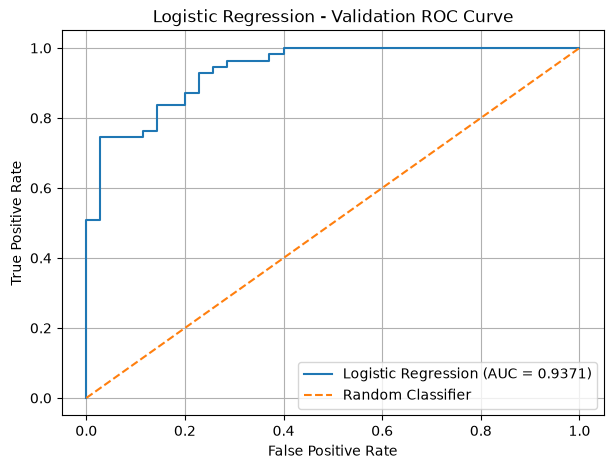

In [49]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_val, y_val_prob) # shows the model performance on differnet threshold


auc = roc_auc_score(y_val, y_val_prob) # measures how well the model separates class 1 from class 0 using predicted probabilities

print("Logistic Regression ROC-AUC:", round(auc, 4))

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - Validation ROC Curve")
plt.legend() # displays label
plt.grid(True)
plt.show()

### Logistic Regression — ROC Curve Interpretation

The Logistic Regression model achieved a validation ROC-AUC score of **0.9371 (93.71%)**, indicating excellent discrimination between winning and non-winning hockey seasons.

The ROC curve remains significantly above the random-classifier diagonal and approaches the top-left region, demonstrating strong classification capability across different probability thresholds.

Although the model achieved only 67.78% accuracy and 47.27% recall at the default classification threshold of 0.5, its high ROC-AUC indicates that it generally assigns higher winning probabilities to actual winning seasons than to non-winning seasons.

This suggests that classification threshold selection may improve the balance between false positives and false negatives.